# 01 · Exploratory Data Analysis
### Revenue Forecast 7D — прогноз виручки користувача за перші 7 днів

**Задача.** Маркетингу потрібно якомога раніше оцінювати, скільки принесуть нові користувачі з різних каналів, не чекаючи 7 днів.
Тому для кожного користувача я прогнозую `revenue_7d` за даними реєстрації та поведінкою в перший день.

**Дані**
- `task_2_users_params.csv` — один рядок на користувача: параметри при реєстрації та таргет `revenue_7d`;
- `task_2_users_actions.csv` — дії за перший день: 4 інтервали по 6 годин на користувача.

**У цьому ноутбуці я перевіряю:**
1. якість даних (дублікати, пропуски, зв'язок таблиць);
2. розподіл таргета;
3. чи не занижена виручка у найновіших користувачів;
4. скільки виручки відомо вже після першого дня;
5. відмінності між каналами, платформами й країнами.

In [11]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))   # щоб працював імпорт з папки src
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

DATA_DIR = Path("../data")

from src.features import load_data, clean_data, build_dataset, TARGET

## 1. Завантаження та якість даних

In [12]:
params_raw, actions_raw = load_data(DATA_DIR)

print("params :", params_raw.shape)
print("actions:", actions_raw.shape)
display(params_raw.head(3))
display(actions_raw.head(4))

params : (1905428, 13)
actions: (6456848, 8)


,id_user,timestamp_reg,age,traffic_type_id,traffic_group_id,gender,country,device_browser,device_brand,device_model,device_platform,device_os,revenue_7d
0,1,2024-09-28 01:32:16.011076+00:00,53,1,1,male,CA,Mobile Silk,Amazon,Fire HD 10 (2021),tablet,Android,0.000
1,1,2024-09-28 01:32:16.011076+00:00,53,1,1,male,CA,Mobile Silk,Amazon,Fire HD 10 (2021),tablet,Android,0.000
2,13,2024-10-18 17:05:48.437175+00:00,53,1,7,male,US,Mobile Silk,Amazon,Fire HD 8 (2022),tablet,Android,0.000


,id_user,timestamp_interval_start,timestamp_interval_end,sum_payments,cnt_payments,sum_credits_spend,cnt_returns,cnt_visit_other_users
0,2672114,2024-08-20 07:07:14.493905+00:00,2024-08-20 13:07:14.493905+00:00,0.000,0,0,0,2
1,2672114,2024-08-20 13:07:14.493905+00:00,2024-08-20 19:07:14.493905+00:00,0.000,0,0,0,0
2,2672114,2024-08-20 19:07:14.493905+00:00,2024-08-21 01:07:14.493905+00:00,0.000,0,0,0,0
3,2672114,2024-08-21 01:07:14.493905+00:00,2024-08-21 07:07:14.493905+00:00,0.000,0,0,0,0


In [13]:
print("Повні дублікати в params:", params_raw.duplicated().sum())
print("Дублікати id_user в params:", params_raw["id_user"].duplicated().sum())
print("Повні дублікати в actions:", actions_raw.duplicated().sum())

missing = pd.concat({"params": params_raw.isna().mean(), "actions": actions_raw.isna().mean()})
display(missing[missing > 0].to_frame("share_missing"))

params, actions = clean_data(params_raw, actions_raw)

print("\nКористувачів у params :", params["id_user"].nunique())
print("Користувачів у actions:", actions["id_user"].nunique())
print("Користувачів без рядків в actions:", (~params["id_user"].isin(actions["id_user"])).sum())
print("\nСкільки інтервалів має кожен користувач:")
display(actions.groupby("id_user").size().value_counts().to_frame("users"))

Повні дублікати в params: 291127
Дублікати id_user в params: 291228
Повні дублікати в actions: 39


share_missing
params country                  0.002
       device_browser           0.004
       device_brand             0.149
       device_model             0.095
       device_platform          0.004
       device_os                0.004


Користувачів у params : 1614200
Користувачів у actions: 1614200
Користувачів без рядків в actions: 0

Скільки інтервалів має кожен користувач:


,users
4,1614191
5,9


**Висновки по якості даних**
- У `params` було 1 905 428 рядків, з них 291 127 (15%) — повні дублікати. Після очищення лишилось **1 614 200 унікальних користувачів**; у `actions` ті самі користувачі, окремих без дій немає.
- Пропуски є лише в `device_brand` (≈15%) і `device_model` (≈9,5%); в інших колонках менше 0,5%. Я заповню їх значенням `unknown`.
- Майже всі користувачі мають рівно 4 інтервали; лише 9 мають 5. На 1,6 млн користувачів це не впливає.

### Перевірка консистентності
`revenue_7d` — виручка за 7 днів, **включно з першим днем**. Тому сума оплат за день 1 не може бути більшою за `revenue_7d`.
Ще перевіряю, чи інтервали дій починаються в момент реєстрації.

In [14]:
day1_sum = actions.groupby("id_user")["sum_payments"].sum().rename("day1_sum")
check = params.set_index("id_user")[[TARGET]].join(day1_sum)

bad = check[check["day1_sum"] > check[TARGET] + 0.01]
print(f"Оплати дня 1 > revenue_7d: {len(bad):,} користувачів ({len(bad) / len(check):.3%})")

first_start = actions.groupby("id_user")["timestamp_interval_start"].min()
shift = (first_start - params.set_index("id_user")["timestamp_reg"]).dt.total_seconds() / 3600
print("\nЗсув першого інтервалу від реєстрації (години):")
display(shift.describe().to_frame("hours").T)

Оплати дня 1 > revenue_7d: 3,676 користувачів (0.228%)

Зсув першого інтервалу від реєстрації (години):


,count,mean,std,min,25%,50%,75%,max
hours,"1,614,200.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000


**Висновки.** Перший інтервал починається рівно в момент реєстрації, тож `actions` — це перші 24 години життя користувача.
У 3 676 користувачів (0,23%) сума оплат дня 1 більша за `revenue_7d`. Можливо, це повернення коштів, але в даних цього не видно. Таких рядків мало, тому я залишаю їх як є.

## 2. Структура таргета

Користувачів: 1,614,200
Платників: 34,389 (2.13%)
ARPU (середня виручка на користувача): $1.127
ARPPU (середня виручка на платника): $52.88
Медіана платника: $9.99

Квантилі виручки платників:


,0.500,0.750,0.900,0.950,0.990,0.999
revenue_$,9.990,26.650,109.960,209.980,809.960,"2,571.035"



Топ-1% платників приносять 30.1% усієї виручки


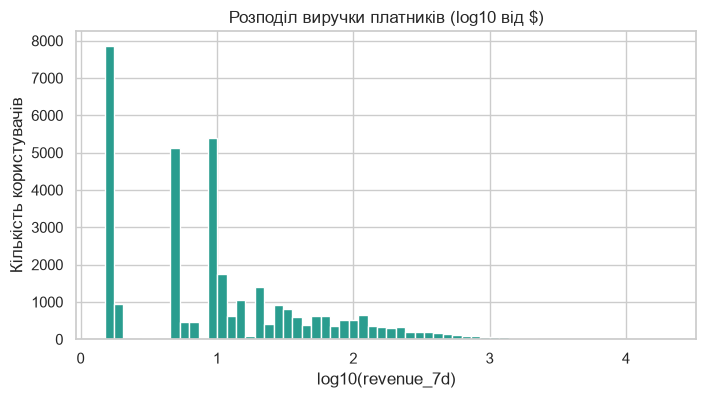

In [15]:
y = params[TARGET]
payers = y[y > 0]

print(f"Користувачів: {len(y):,}")
print(f"Платників: {len(payers):,} ({len(payers) / len(y):.2%})")
print(f"ARPU (середня виручка на користувача): ${y.mean():.3f}")
print(f"ARPPU (середня виручка на платника): ${payers.mean():.2f}")
print(f"Медіана платника: ${payers.median():.2f}")

print("\nКвантилі виручки платників:")
display(payers.quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).to_frame("revenue_$").T)

top_1pct = payers.sort_values(ascending=False).head(int(len(payers) * 0.01))
print(f"\nТоп-1% платників приносять {top_1pct.sum() / payers.sum():.1%} усієї виручки")

plt.figure(figsize=(8, 4))
plt.hist(np.log10(payers), bins=60, color="#2a9d8f")
plt.title("Розподіл виручки платників (log10 від $)")
plt.xlabel("log10(revenue_7d)")
plt.ylabel("Кількість користувачів")
plt.show()

**Висновки.** Платять лише **2,13%** користувачів (34 389). Медіанний платник витрачає 9,99, а середній — 52,88, бо розподіл дуже скошений: 99-й перцентиль — 810, 99,9-й — 2 571.
**Топ-1% платників дають 30,1% усієї виручки.**
Тож таргет має дуже багато нулів і важкий правий хвіст; це впливає і на вибір моделі, і на вибір метрик.

## 3. Чи не занижена виручка у найновіших користувачів?
Якщо дані вивантажили менш ніж через 7 днів після реєстрації останніх користувачів, їхній `revenue_7d` був би занижений. Дивлюсь на частку платників і ARPU по днях реєстрації.

Реєстрації: 2024-08-01 00:00:01.423192+00:00 → 2024-11-19 23:59:57.920821+00:00


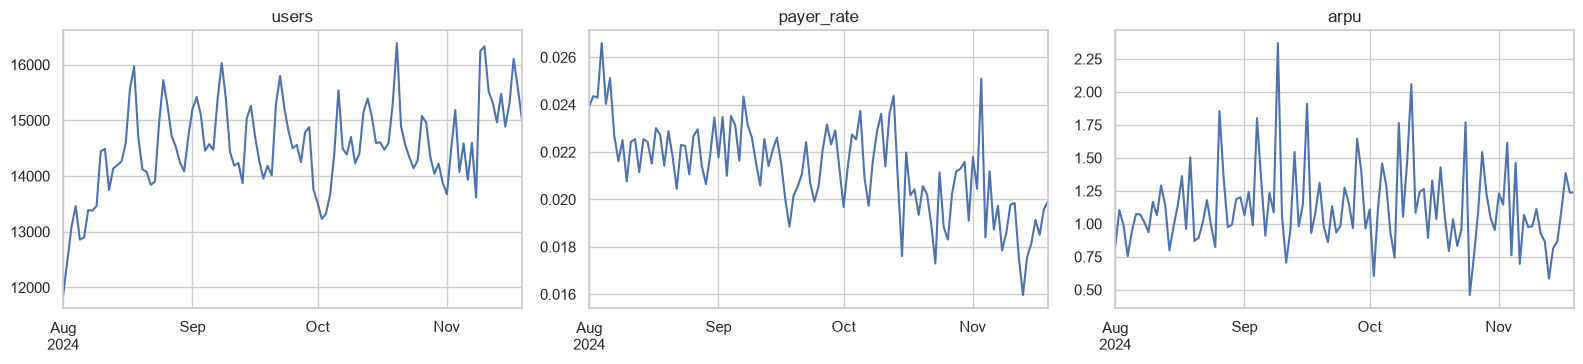

,users,payer_rate,arpu
reg_day,,,
2024-11-12 00:00:00+00:00,15311,0.018,0.866
2024-11-13 00:00:00+00:00,14965,0.016,0.586
2024-11-14 00:00:00+00:00,15478,0.018,0.815
2024-11-15 00:00:00+00:00,14887,0.018,0.868
2024-11-16 00:00:00+00:00,15308,0.019,1.106
2024-11-17 00:00:00+00:00,16104,0.019,1.384
2024-11-18 00:00:00+00:00,15582,0.020,1.235
2024-11-19 00:00:00+00:00,15005,0.020,1.239


In [16]:
params["is_payer"] = params[TARGET] > 0
params["reg_day"] = params["timestamp_reg"].dt.floor("D")
daily = params.groupby("reg_day").agg(users=(TARGET, "size"), payer_rate=("is_payer", "mean"), arpu=(TARGET, "mean"))

print("Реєстрації:", params["timestamp_reg"].min(), "→", params["timestamp_reg"].max())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ["users", "payer_rate", "arpu"]):
    daily[col].plot(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

display(daily.tail(8))

**Висновок.** Дані охоплюють реєстрації з 1 серпня по 19 листопада 2024. Частка платників у останні дні (≈1,6–2,0%) не падає, тож ознак занижених даних для свіжих користувачів немає. ARPU по днях сильно коливається (від 0,59 до 1,38 у останні 8 днів) через кількох великих платників.

## 4. Скільки виручки відомо вже після першого дня?
Якщо багато користувачів платять у перший же день, то задачу можна наївно вирішити так: «виручка за тиждень = виручка за день 1».
Тому цей простий варіант треба обов'язково порівняти з моделлю.

In [17]:
day1_cnt = actions.groupby("id_user")["cnt_payments"].sum().rename("day1_cnt")
t = params.set_index("id_user")[[TARGET]].join(day1_sum).join(day1_cnt)
t["paid_day1"] = t["day1_cnt"] > 0
t["paid_7d"] = t[TARGET] > 0

table = pd.crosstab(t["paid_day1"], t["paid_7d"], margins=True)
table.index = ["не платив у день 1", "платив у день 1", "всього"]
table.columns = ["не платник за 7д", "платник за 7д", "всього"]
display(table)

late = t[(~t["paid_day1"]) & t["paid_7d"]]
print(f"Частка виручки 7д, яку вже принесено в день 1: {t['day1_sum'].sum() / t[TARGET].sum():.1%}")
print(f"Платників, які не платили в день 1 («пізні»): {len(late) / t['paid_7d'].sum():.1%}")
print(f"Виручка «пізніх» платників від усієї: {late[TARGET].sum() / t[TARGET].sum():.1%}")

,не платник за 7д,платник за 7д,всього
не платив у день 1,1579642,9420,1589062
платив у день 1,169,24969,25138
всього,1579811,34389,1614200


Частка виручки 7д, яку вже принесено в день 1: 36.6%
Платників, які не платили в день 1 («пізні»): 27.4%
Виручка «пізніх» платників від усієї: 19.9%


**Висновки.**
- **36,6%** виручки за 7 днів надходить уже в перший день.
- Із 34 389 платників 24 969 платили вже в день 1. Інші **9 420 (27,4%)** — «пізні» платники, які в перший день нічого не купили; вони приносять 19,9% виручки.
- Є 169 користувачів, які платили в день 1, але мають `revenue_7d = 0`. Це частина тієї самої аномалії з перевірки консистентності.

Отже, у користувачів, які вже заплатили, прогноз сильно спирається на день 1. А справжня цінність моделі — у передбаченні «пізніх» платників.
Тому далі я оцінюю модель окремо на користувачах без оплат у день 1.

## 5. Сегменти

In [18]:
def segment_table(col, min_users=1000, top=12):
    g = params.groupby(col).agg(users=(TARGET, "size"), payer_rate=("is_payer", "mean"),
                                arpu=(TARGET, "mean"), revenue=(TARGET, "sum"))
    g["arppu"] = g["revenue"] / (g["payer_rate"] * g["users"])
    g = g[g["users"] >= min_users]
    return g.sort_values("arpu", ascending=False).head(top)

print("traffic_type_id")
display(segment_table("traffic_type_id"))
print("device_platform")
display(segment_table("device_platform"))
print("country (лише країни, де не менше 1000 користувачів)")
display(segment_table("country"))

traffic_type_id


,users,payer_rate,arpu,revenue,arppu
traffic_type_id,,,,,
2,707505,0.027,1.460,"1,033,022.530",53.616
3,95567,0.016,0.956,"91,317.800",61.246
1,811128,0.017,0.856,"694,226.310",50.930


device_platform


,users,payer_rate,arpu,revenue,arppu
device_platform,,,,,
desktop,137108,0.024,1.771,"242,785.360",74.269
tablet,33474,0.020,1.503,"50,320.710",75.218
mobile,1435768,0.021,1.055,"1,515,156.860",50.004


country (лише країни, де не менше 1000 користувачів)


,users,payer_rate,arpu,revenue,arppu
country,,,,,
CH,1770,0.036,3.131,"5,542.090",86.595
NO,3128,0.056,2.597,"8,122.160",46.149
FI,2628,0.030,2.153,"5,658.500",72.545
DK,3130,0.035,2.065,"6,461.980",58.216
IL,3195,0.031,2.009,"6,419.180",64.840
NZ,16692,0.025,1.989,"33,197.620",80.970
AU,50235,0.036,1.923,"96,590.310",53.453
SE,5073,0.034,1.801,"9,136.660",53.431
CA,88251,0.024,1.402,"123,696.890",57.802


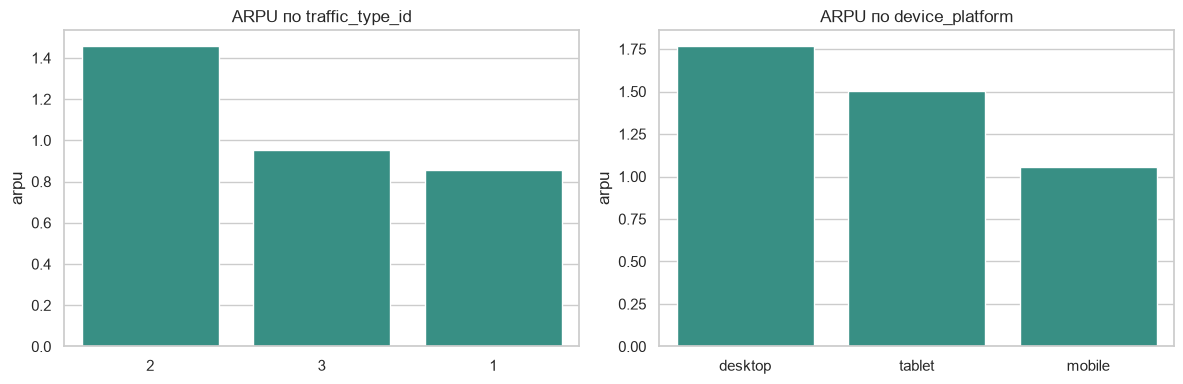

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["traffic_type_id", "device_platform"]):
    g = segment_table(col)
    sns.barplot(x=g.index.astype(str), y=g["arpu"], ax=ax, color="#2a9d8f")
    ax.set_title(f"ARPU по {col}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Висновки.**
- **Тип трафіку:** тип 2 найкращий — ARPU 1,46 і 2,7% платників. Для типів 1 і 3 — 0,86 і 0,96 та 1,7% і 1,6% платників. Тип 2 приносить на 70% більше на користувача, ніж тип 1.
- **Платформа:** desktop дає ARPU 1,77, tablet — 1,50, mobile — 1,06. Ці платформи платять приблизно однаково часто (2,0–2,4%), різниця в тому, що desktop і tablet витрачають більше на одного платника (74–75 проти 50 на mobile).
- **Країни:** найвищий ARPU у CH (3,13), NO (2,60) і FI (2,15). Але найбільша країна, US, має ARPU 1,38 і дає близько 69% усієї виручки (1,25 млн із 1,82 млн). Малі країни я відфільтрував (< 1000 користувачів), бо там середнє занадто шумне.

## 6. Ознаки першого дня та таргет
Для кореляції беру коефіцієнт Спірмена: він не залежить від викидів, а в нас важкий хвіст.

Ознаки, які в усіх однакові (прибрано): ['d1_returns']


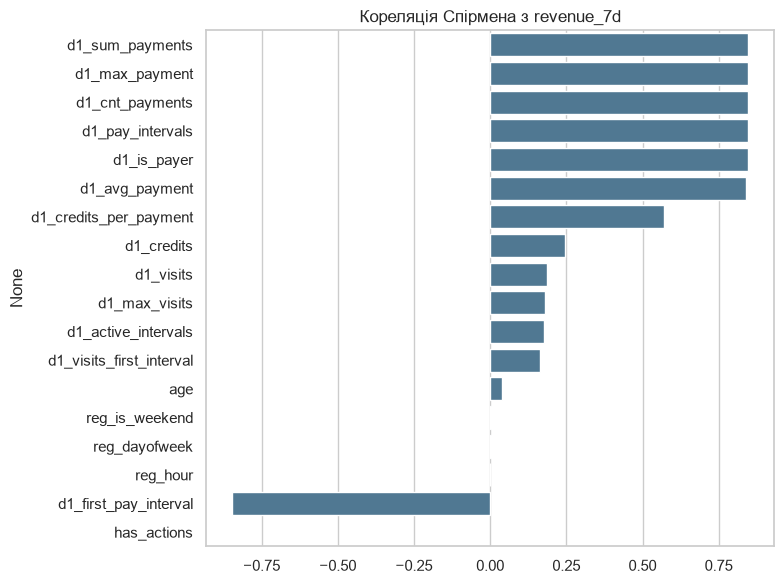

In [20]:
df, constant_cols = build_dataset(params.drop(columns=["is_payer", "reg_day"]), actions)
print("Ознаки, які в усіх однакові (прибрано):", constant_cols)

numeric = df.select_dtypes("number").drop(columns=["id_user"])
corr = numeric.corr(method="spearman")[TARGET].drop(TARGET).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=corr.values, y=corr.index, color="#457b9d")
plt.title("Кореляція Спірмена з revenue_7d")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Висновки.**
- Найсильніше зв'язані з таргетом оплати першого дня: `d1_sum_payments`, `d1_cnt_payments`, `d1_is_payer` (кореляція ≈ 0,85). Також `d1_first_pay_interval` має кореляцію ≈ −0,85: що раніше була перша оплата, то вища виручка.
- Візити (`d1_visits`, `d1_active_intervals`) — слабша кореляція (≈ 0,18). Вік, година й день реєстрації майже не корелюють лінійно з таргетом.
- Сталу ознаку `d1_returns` я прибрав: `cnt_returns` однаковий у всіх користувачів.

## Підсумок EDA

| Знахідка | Що з цього випливає |
|---|---|
| 15% дублікатів у `params` | Видаляю при очищенні |
| 2,13% платників, топ-1% платників = 30% виручки | Таргет має багато нулів і важкий хвіст → потрібна відповідна модель і метрики |
| 36,6% виручки відомо вже в день 1 | Обов'язковий baseline «день 1 = тиждень»; окрема оцінка на користувачах без оплат у день 1 |
| Тип 2 і desktop приносять найбільше на користувача | Маркетингу важлива точність по каналах (когортах) |
| Малі країни й рідкісні моделі пристроїв | Рідкісні значення об'єднаю в `rare` |
| Дані впорядковані в часі | Розбиваю за часом: train → valid → test, без перемішування |

Далі: `02_modeling.ipynb`